# Multinominal logistic regression life span to predict danger index

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import ShuffleSplit
from sklearn.model_selection import KFold
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn import linear_model
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.multiclass import OneVsOneClassifier
from sklearn.metrics import ConfusionMatrixDisplay

df = pd.read_csv("dataset_2191_sleep.csv")
df= df.dropna()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   body_weight           62 non-null     float64
 1   brain_weight          62 non-null     float64
 2   max_life_span         62 non-null     str    
 3   gestation_time        62 non-null     str    
 4   predation_index       62 non-null     int64  
 5   sleep_exposure_index  62 non-null     int64  
 6   danger_index          62 non-null     int64  
 7   total_sleep           62 non-null     str    
dtypes: float64(2), int64(3), str(3)
memory usage: 4.0 KB


In [2]:
df.head()

,body_weight,brain_weight,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index,total_sleep
0,6654.000,5712.0,38.6,645,3,5,3,3.3
1,1.000,6.6,4.5,42,3,1,3,8.3
2,3.385,44.5,14,60,1,1,1,12.5
3,0.920,5.7,?,25,5,2,3,16.5
4,2547.000,4603.0,69,624,3,5,4,3.9


Next cells filter the data to have only what is used and to take out unkown values(?)

In [3]:
df = df.replace("?", np.nan)
df = df.dropna()
df.info()

<class 'pandas.DataFrame'>
Index: 51 entries, 0 to 60
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   body_weight           51 non-null     float64
 1   brain_weight          51 non-null     float64
 2   max_life_span         51 non-null     str    
 3   gestation_time        51 non-null     str    
 4   predation_index       51 non-null     int64  
 5   sleep_exposure_index  51 non-null     int64  
 6   danger_index          51 non-null     int64  
 7   total_sleep           51 non-null     str    
dtypes: float64(2), int64(3), str(3)
memory usage: 3.6 KB


In [4]:
df["max_life_span"] = df["max_life_span"].astype(float)
df["danger_index"] = df["danger_index"].astype(float)

In [5]:
df.drop(columns=['body_weight','brain_weight','gestation_time','predation_index','sleep_exposure_index','total_sleep'],inplace=True)

C:\Users\meisp\AppData\Local\Temp\ipykernel_9840\3651083323.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['body_weight','brain_weight','gestation_time','predation_index','sleep_exposure_index','total_sleep'],inplace=True)


In [9]:
df.info()

<class 'pandas.DataFrame'>
Index: 51 entries, 0 to 60
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   max_life_span  51 non-null     float64
 1   danger_index   51 non-null     float64
dtypes: float64(2)
memory usage: 1.2 KB


In [6]:
danger = df['danger_index'] 
danger_counts = danger.value_counts() 
print(danger_counts)

danger_index
1.0    15
2.0    12
4.0     9
3.0     8
5.0     7
Name: count, dtype: int64


Because of imbalanced data chose to do stratified shuffle split

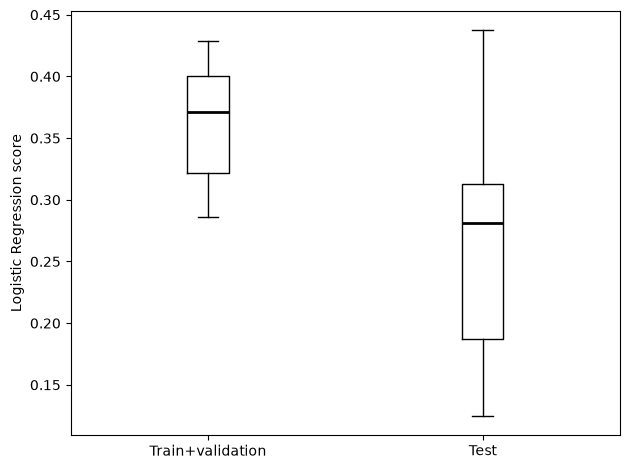

0.37142857142857144
0.28125


In [18]:
mlifespan = df['max_life_span']

y = df['danger_index'].to_numpy()
x = np.array(mlifespan).reshape(-1,1)

n_trials = 10
score_tv = list()
score_te = list()
split = StratifiedShuffleSplit(n_splits=n_trials, train_size=0.7,random_state=42)
for train, test in split.split(x, y):
    x_tv,y_tv = x[train], y[train]
    x_te,y_te = x[test], y[test]

    ovr = OneVsRestClassifier(LogisticRegression(max_iter=1000,C=np.inf)).fit(x_tv, y_tv)
    score_tv.append(ovr.score(x_tv,y_tv))
    score_te.append(ovr.score(x_te,y_te))

plt.boxplot([score_tv,score_te],medianprops=dict(color='k', linewidth=2))
plt.ylabel('Logistic Regression score')
plt.xticks([1,2],labels=['Train+validation','Test'])
plt.tight_layout()
plt.show()

print(np.median(score_tv))
print(np.median(score_te))

In the next cell looks at what is the best k-fold for this data.

In [19]:
from sklearn.model_selection import cross_val_score

mlifespan = df['max_life_span']

y = df['danger_index'].to_numpy()
x = np.array(mlifespan).reshape(-1,1)

ovr = OneVsRestClassifier(LogisticRegression(max_iter=1000))

n_repeats = 50

# Number of folds in k-fold
ks = [ 2, 3, 4, 5,]
print("\nk-fold")
for k in ks:
    cv = RepeatedStratifiedKFold(n_splits=k, n_repeats=n_repeats // 5, random_state=42)
    scores = cross_val_score(ovr, x, y, cv=cv, n_jobs=4)
    print(f"k={k:2d}  mean={scores.mean():.4f}  std={scores.std():.4f}")


k-fold
k= 2  mean=0.3078  std=0.0688
k= 3  mean=0.2922  std=0.0752
k= 4  mean=0.3053  std=0.0809
k= 5  mean=0.2969  std=0.1013


Choose k-fold= 2 best mean for logistic regression score and least std. Now I will compare the OnevsRest model and to OnevsOne model.

In [20]:
mlifespan = df['max_life_span']

y = df['danger_index'].to_numpy()
x = np.array(mlifespan).reshape(-1,1)

ovr = OneVsRestClassifier(LogisticRegression(max_iter=1000))
ovo = OneVsOneClassifier(LogisticRegression(max_iter=1000))
models = [ovr,ovo]

param_grid = {'estimator__C': np.logspace(-4,3,num=8)}

n_outer_splits = 2
n_repeats = 5
n_inner_splits = 2

test_scores = np.zeros((n_outer_splits*n_repeats,len(models)))
model_choice = np.zeros(n_outer_splits*n_repeats)
param_choice = np.zeros(n_outer_splits*n_repeats)

outercv = RepeatedStratifiedKFold(n_splits=n_outer_splits,n_repeats=n_repeats,random_state=42)
innercv = StratifiedKFold(n_splits=n_inner_splits,shuffle=True,random_state=42)

for k, (train, test) in enumerate(outercv.split(x,y)):
    x_tv,y_tv = x[train], y[train]
    x_te,y_te = x[test], y[test]

    estimators = list()
    scores = list()
    param = list()
    for model in models:
        param_cv = GridSearchCV(model,param_grid,n_jobs=4,cv=innercv)
        param_cv.fit(x_tv,y_tv)
        scores.append(param_cv.best_score_)
        estimators.append(param_cv.best_estimator_)
        param.append(param_cv.best_params_['estimator__C'])

    choose = int(np.argmax(scores))
    model_choice[k] = choose
    param_choice[k] = param[choose]
    for j, model in enumerate(estimators):
        model.fit(x_tv,y_tv)
        test_scores[k,j] = model.score(x_te,y_te)

print(np.mean(model_choice))
print(np.mean(test_scores[:,0]-test_scores[:,1]))

0.2
0.015384615384615385


In [21]:
print(param_choice)

[1.e-01 1.e-01 1.e-01 1.e+00 1.e-01 1.e-04 1.e-01 1.e-03 1.e-02 1.e-03]


The onevsoneclassifier is better bc this score is closer to zero. I will redo the model disicions on this model to see if the k fold would still be the same. The print param_choice shows the best choice for c in each case, the most stable choice is 1.e-01, because that there 5 times, the other 5 are 4 different ones. 

In [22]:
mlifespan = df['max_life_span']

y = df['danger_index'].to_numpy()
x = np.array(mlifespan).reshape(-1,1)

ovo = OneVsOneClassifier(LogisticRegression(max_iter=1000, C=1.e-01))

n_repeats = 50

# Number of folds in k-fold
ks = [ 2, 3, 4, 5,]
print("\nk-fold")
for k in ks:
    cv = RepeatedStratifiedKFold(n_splits=k, n_repeats=n_repeats // 5, random_state=42)
    scores = cross_val_score(ovr, x, y, cv=cv, n_jobs=4)
    print(f"k={k:2d}  mean={scores.mean():.4f}  std={scores.std():.4f}")



k-fold
k= 2  mean=0.3078  std=0.0688
k= 3  mean=0.2922  std=0.0752
k= 4  mean=0.3053  std=0.0809
k= 5  mean=0.2969  std=0.1013


K-fold = 2 is still the best fit, next cell is final model with c=1e-01 and k=2. Cell below is full model

In [27]:
mlifespan = df['max_life_span']

y = df['danger_index'].to_numpy()
x = np.array(mlifespan).reshape(-1,1)

ovo = OneVsOneClassifier(LogisticRegression(max_iter=1000, C=1.e-01))
skf = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)
scores = cross_val_score(ovo, x, y, cv=skf)

ovo.fit(x,y)
print(ovo.score(x,y))
print(ovo.estimators_[0].coef_)

0.3333333333333333
[[-0.03747331]]


[[10  5  0  0  0]
 [ 5  7  0  0  0]
 [ 1  7  0  0  0]
 [ 6  3  0  0  0]
 [ 7  0  0  0  0]]


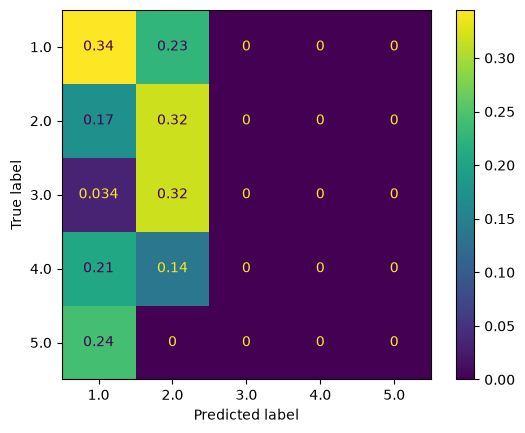

In [24]:
from sklearn.metrics import confusion_matrix
yhat = ovo.predict(x)
confmat = confusion_matrix(y,yhat)
print(confmat)
ConfusionMatrixDisplay.from_estimator(ovo,x,y,normalize='pred')
plt.show()

Danger indax cannot be predicted by max life span.

## Some visualitation

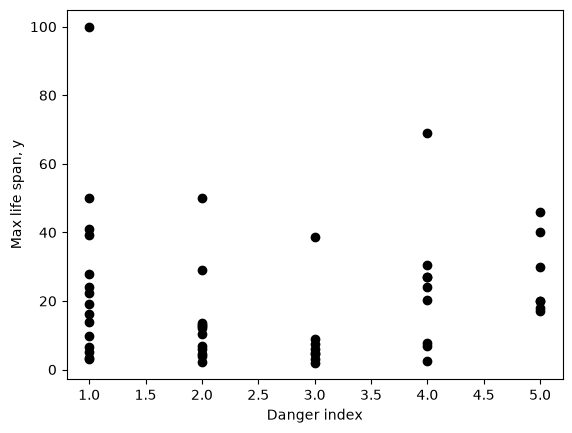

In [25]:
plt.scatter(df['danger_index'],df['max_life_span'],c='k') # the c argument specifies the color, 'k' corresponds to 'black'
plt.ylabel('Max life span, y')
plt.xlabel('Danger index')
plt.show()

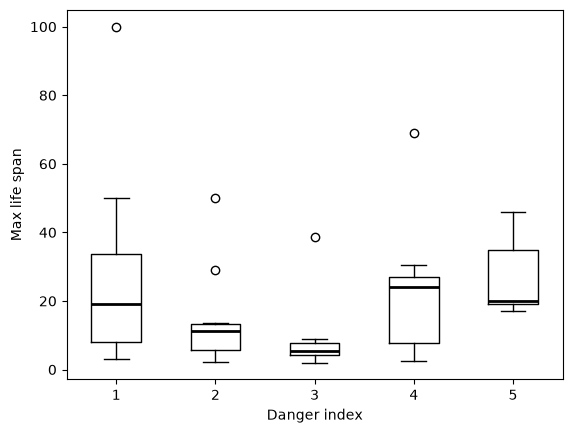

In [26]:
danger1 = df[df['danger_index']==1.0]['max_life_span']
danger2 = df[df['danger_index']==2.0]['max_life_span']
danger3 = df[df['danger_index']==3.0]['max_life_span']
danger4 = df[df['danger_index']==4.0]['max_life_span']
danger5 = df[df['danger_index']==5.0]['max_life_span']

plt.boxplot([danger1,danger2,danger3,danger4,danger5],medianprops=dict(color='k', linewidth=2))
plt.ylabel('Max life span')
plt.xlabel('Danger index')
plt.show()